# 06 Full Model Comparison

**Scientific question.** How do all 21 controls compare on identical development targets?

**Learning objectives.** Read models by family, reconcile metrics and assess input parity.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### All model families and exact target alignment

Statistical models use lag or innovation dynamics. Linear, Ridge, Lasso
and Elastic Net compare readout regularization. SVR uses a kernel and
bounded fit support. Forest and boosting ensembles partition a supplied
feature space. MLP flattens windows; LSTM and GRU use gated temporal
updates; CNN and TCN operate by shared filters and controlled dilation.
The Transformer uses historical patch attention, and compact TFT uses
variable selection and historical gating/attention. NARX explicitly
conditions nonlinear lag dynamics on past exogenous speed. Sparse LPV
uses varying coefficients and, in its two-stage variant, proxy residuals.

The baseline checkpoint lineage is preserved. New inference/mask/causal
audit uses the same vibration as PI-SRC, and the separate RPM-withheld
controls determine whether observed speed helps within a matched family.
Companion Chapter 17 goes through all 21 algorithms and Chapter 23
relates observed outcomes to their assumptions.

### Which statistical or learning assumptions does each baseline test?

Let $\mathbf{x}_{<t}$ and $\mathbf{n}_{<t}$ denote observed vibration and
RPM histories. A historical representation $v_t$ contains only permitted
rows. Below $b$ denotes an intercept and $w$ a fitted coefficient vector.
Some models operate on the supplied vibration lags, while a tabular family
can receive richer permitted features. Inspect the configuration table for
the actual width, fit scope and effective data history of each comparison.

| Model | How it turns history into a prediction |
| --- | --- |
| AR | Predicts the level by a weighted combination of positive vibration lags. It tests stationary linear dependence without an operating input. |
| ARMA | Adds coefficients on earlier forecast errors to the AR predictor. Initial state and causal innovation recursion determine the early predictions. |
| ARIMA | Fits the autoregressive and innovation relation on a differenced signal, then reconstructs the prediction at level using observed past vibration. |
| ARX | Adds measured exogenous history to a linear lag relation. Speed withholding tests the incremental value of that input within the matched fit. |
| NARX | Uses a parameterized nonlinear map of past vibration and exogenous history. It can express state-dependent lag effects with a short fixed context. |
| Sparse LPV–AR | Multiplies each vibration lag by speed-basis values and sparsely selects the resulting scheduled columns before coefficient refit. |
| Sparse LPV–ARMA | Adds scheduled proxy innovations from the first stage. Its benchmark isolates a strict causal refit on protected sparse supports. |
| Linear Regression | Fits $b+w^Tv_t$ by squared-error minimization without coefficient shrinkage. Its success tests the predictive sufficiency of the chosen inputs. |
| Ridge | Augments squared error with $\ell_2$ weight penalty. Correlated historical coordinates can yield more stable forecasts after shrinkage. |
| Lasso | Uses an $\ell_1$ penalty that can drop unnecessary feature columns before evaluation. Coefficient support is a property of this fit. |
| Elastic Net | Couples $\ell_1$ and $\ell_2$ penalties. This tests the value of retaining groups of related features while encouraging sparsity. |
| SVR | Predicts with a kernel expansion supported on selected training examples, using an interval-insensitive error loss. Training subsets control cost. |
| Random Forest | Averages predictors from randomized trees and tests whether threshold interactions in the input features generalize. |
| Gradient Boosting | Fits successive small tree updates to improve the current loss. Tuning controls tree complexity, shrinkage and number of iterations. |
| MLP | Learns a nonlinear feedforward transformation of a flattened past window. It has no recurrent state and no explicit mesh phase. |
| LSTM | Learns input, forget and output gates for hidden and cell state so earlier examples can persist through the context. |
| GRU | Blends earlier state with a reset-gated candidate state. It uses fewer gate groups than the comparable LSTM architecture. |
| CNN | Learns local temporal filters across historical samples. Shared filters are a time-structured inductive bias even without angular alignment. |
| TCN | Uses a stack of dilated causal filters to enlarge its historical receptive field while limiting filter count. |
| Time Series Transformer | Embeds historical patches and relates them through attention. Learnable attention weights operate within the allowed past context. |
| Temporal Fusion Transformer | Uses compact variable selection, gating and attention on historical context. The local checkpoint does not implement all modules of the original multihorizon architecture. |

The rows test families under measured configurations. They cannot isolate
an architecture alone when feature processing, regularization, training
width, and guarded tuning budgets differ. The checkpoint lineage and matched
ablations show which claims survive tighter controls.

In [2]:
coverage = table("results/metrics/model_coverage.csv")
if coverage is not None:
    display(coverage)
ranking = table("results/metrics/all_model_comparison.csv")
base = forecast("results/predictions/baselines_sigvalid.npz")
src = forecast("results/predictions/src_sigvalid.npz")
archive = forecast("results/predictions/archived_src_sigvalid.npz")
if base and src and archive:
    align_forecasts(base, src, archive)

,model,status,fit_evidence,evaluation,limitation
0,ar,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
1,arma,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
2,arima,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
3,arx,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
4,sparse_lpv_ar,DONE,protected_guarded_support_refit,independent_checkpoint_replay,Protected single selected seed availability where stochastic
5,sparse_lpv_arma,DONE,protected_guarded_support_refit,independent_checkpoint_replay,Protected single selected seed availability where stochastic
6,linear,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
7,ridge,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
8,lasso,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic
9,elastic_net,DONE,protected_guarded_training,independent_checkpoint_replay,Protected single selected seed availability where stochastic


,model,mse,rmse,mae,bias,fit_s,warm_median_ms,parameters,checkpoint_bytes,scope
0,archived_src_corrected,0.317788,0.563727,0.448410,-0.003392,NaN,188.792637,2789.0,NaN,archived_checkpoint_replay
1,archived_src_earlier_corrected,0.317816,0.563752,0.449606,-0.004541,NaN,NaN,NaN,NaN,archived_forecast_only
2,archived_src_local_corrected,0.318606,0.564452,0.448904,-0.003572,NaN,184.808112,2789.0,NaN,archived_checkpoint_replay
3,archived_src_earlier,0.325353,0.570397,0.455213,-0.014631,NaN,NaN,NaN,NaN,archived_forecast_only
4,archived_src_base,0.325630,0.570640,0.454468,-0.012469,NaN,185.983217,2789.0,NaN,archived_checkpoint_replay
5,primary_pi_src,0.329973,0.574433,0.456412,0.007643,4.265193,484.886787,1456.0,32494.0,new PI-SRC
6,linear,0.367386,0.606123,0.482352,0.008699,3.141523,951.884354,530.0,12738.0,replayed comparator
7,ridge,0.368059,0.606678,0.482731,0.003971,1.176394,994.576578,530.0,12735.0,replayed comparator
8,sparse_lpv_arma,0.371406,0.609430,0.483517,-0.008890,5.188056,87.959670,840.0,8908.0,replayed comparator
9,lasso,0.378298,0.615060,0.489438,-0.003721,2.430754,953.803781,367.0,11701.0,replayed comparator


27 reported model scores independently rederived


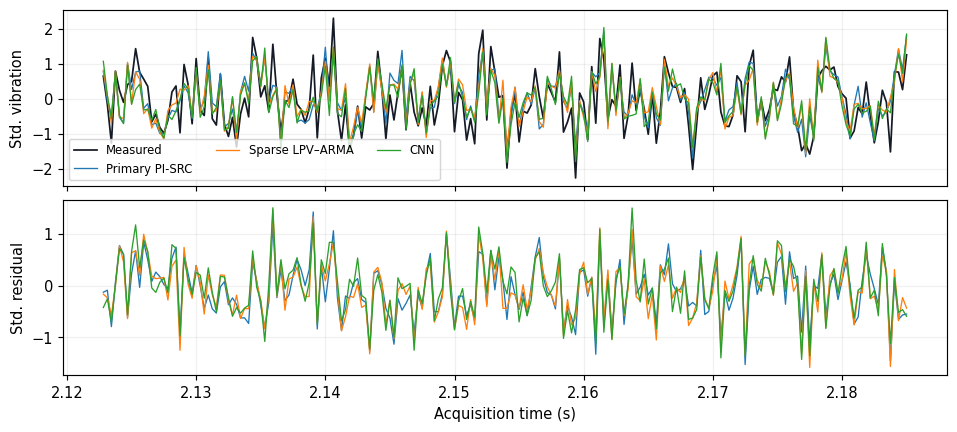

In [3]:
samples = {k:v for bundle in (base,src,archive) for k,v in bundle.items()}
if ranking is not None and samples:
    cols = ["model","mse","rmse","mae","bias","fit_s","warm_median_ms","parameters",
            "checkpoint_bytes","scope"]
    display(ranking[[k for k in cols if k in ranking]].sort_values("mse"))
    rebuilt = []
    for row in ranking.itertuples(index=False):
        assert row.model in samples, row.model
        mse = np.mean((samples["actual"]-samples[row.model])**2)
        rebuilt.append((row.model,mse))
        np.testing.assert_allclose(mse,row.mse,atol=1e-11,rtol=0)
    print(len(rebuilt), "reported model scores independently rederived")
draw_forecast(samples, {"primary_pi_src":"Primary PI-SRC",
                        "sparse_lpv_arma":"Sparse LPV–ARMA",
                        "cnn":"CNN"})

In [4]:
parity = table("results/metrics/vibration_rpm_parity.csv")
if parity is not None:
    display(parity[["model","measured_mse","vibration_only_mse",
                    "delta_measured_minus_vibration_only"]])
configs = table("results/metrics/baseline_configs.csv")
if configs is not None:
    display(configs)

,model,measured_mse,vibration_only_mse,delta_measured_minus_vibration_only
0,arx,0.443197,0.440779,0.002418
1,narx,0.383150,0.451529,-0.068379
2,mlp,0.406424,0.459911,-0.053487
3,lstm,0.408813,0.446419,-0.037606
4,gru,0.416062,0.445067,-0.029005
5,cnn,0.394638,0.443821,-0.049183
6,tcn,0.408577,0.443486,-0.034909
7,transformer,0.509394,0.512916,-0.003522
8,tft,0.967099,0.953319,0.013780


,model,family,checkpoint_sha256,selected_config,guarded_fold_rows,fit_scope
0,ar,statistical,3f1571ae167c572974afbb4ac86dc79a583a4af3589cc26f24fa7a101c802f6e,"{""family"": ""ar"", ""p"": 96, ""q"": 0, ""ridge"": 0.0, ""speed_lags"": []}",21,full_training_refit
1,arma,statistical,83eb59c0ca23da8884053f18b209d9d2fa1a17b34a093764ff3e6951d3a36a23,"{""family"": ""arma"", ""p"": 96, ""q"": 2, ""ridge"": 0.0, ""speed_lags"": []}",36,full_training_refit
2,arima,statistical,316057b82b7db94e9b05b3ba10c3a582fcd3862c14c463c7774803b3fe7a71fe,"{""family"": ""arima"", ""p"": 96, ""q"": 2, ""ridge"": 0.0, ""speed_lags"": []}",36,full_training_refit
3,arx,statistical,eab106d6324bec812b944569939aa806fdf670a935f9898e28d7c5c5ec8684f3,"{""family"": ""arx"", ""p"": 96, ""q"": 0, ""ridge"": 0.002, ""speed_lags"": [1, 17, 65, 257]}",54,full_training_refit
4,sparse_lpv_ar,statistical,d2cc6d9304d8931a835ec9778d50f9527b9930af8eb0fdf0e55a124181cebd66,"{""basis"": ""shifted_legendre"", ""basis_terms"": 8, ""schedule_lag"": 1, ""stage1_ar"": 240, ""stage2_ar"": 0, ""stage2_ma"": 0,...",0,full_training_support_refit
5,sparse_lpv_arma,statistical,2c9dd3987642a86076a69802aa560d82cfe65425ad79d2d9d946976b5e1b3a77,"{""basis"": ""shifted_legendre"", ""basis_terms"": 8, ""schedule_lag"": 1, ""stage1_ar"": 240, ""stage2_ar"": 135, ""stage2_ma"": ...",0,full_training_support_refit
6,linear,tabular,a5889b5fba34c02d9efcdbf5ff96b6ef0cf13a4cfd993c436564042eb9c15373,"{""alpha"": 1.0, ""c"": 3.0, ""epochs"": 28, ""epsilon"": 0.1, ""family"": ""linear"", ""feature_set"": ""physics"", ""gamma_scale"": ...",9,full_training_refit
7,ridge,tabular,ee8229f16974a82ec51edb9002690fddd3c3ac121b3df3953f079b3418a84129,"{""alpha"": 80.0, ""c"": 3.0, ""epochs"": 28, ""epsilon"": 0.1, ""family"": ""ridge"", ""feature_set"": ""physics"", ""gamma_scale"": ...",36,full_training_refit
8,lasso,tabular,f3cfbe093cbafccb3b7a6152117d7dcaa2257d81c609f5d84f3a1eda71caf85d,"{""alpha"": 0.0015, ""c"": 3.0, ""epochs"": 28, ""epsilon"": 0.1, ""family"": ""lasso"", ""feature_set"": ""physics"", ""gamma_scale""...",27,full_training_refit
9,elastic_net,tabular,443bb40537a87e2d434c05e8ab06c116a44f3740697bb69cfc3dfa310f3df71b,"{""alpha"": 0.0025, ""c"": 3.0, ""epochs"": 28, ""epsilon"": 0.1, ""family"": ""elastic_net"", ""feature_set"": ""physics"", ""gamma_...",36,full_training_refit


Checked required families: 21/21
Selected minus archive MSE: +0.012186
Selected improvement over leading required baseline: 10.18%


,model,reference,delta_mse,block_samples,interval_low,interval_high,draws
1,ar,primary_pi_src,0.110593,640,0.098254,0.121597,2000
19,sparse_lpv_arma,primary_pi_src,0.041432,640,0.036319,0.047242,2000
22,linear,primary_pi_src,0.037412,640,0.032403,0.041436,2000
52,cnn,primary_pi_src,0.064665,640,0.056022,0.073982,2000
64,archived_src_corrected,primary_pi_src,-0.012186,640,-0.014521,-0.010361,2000


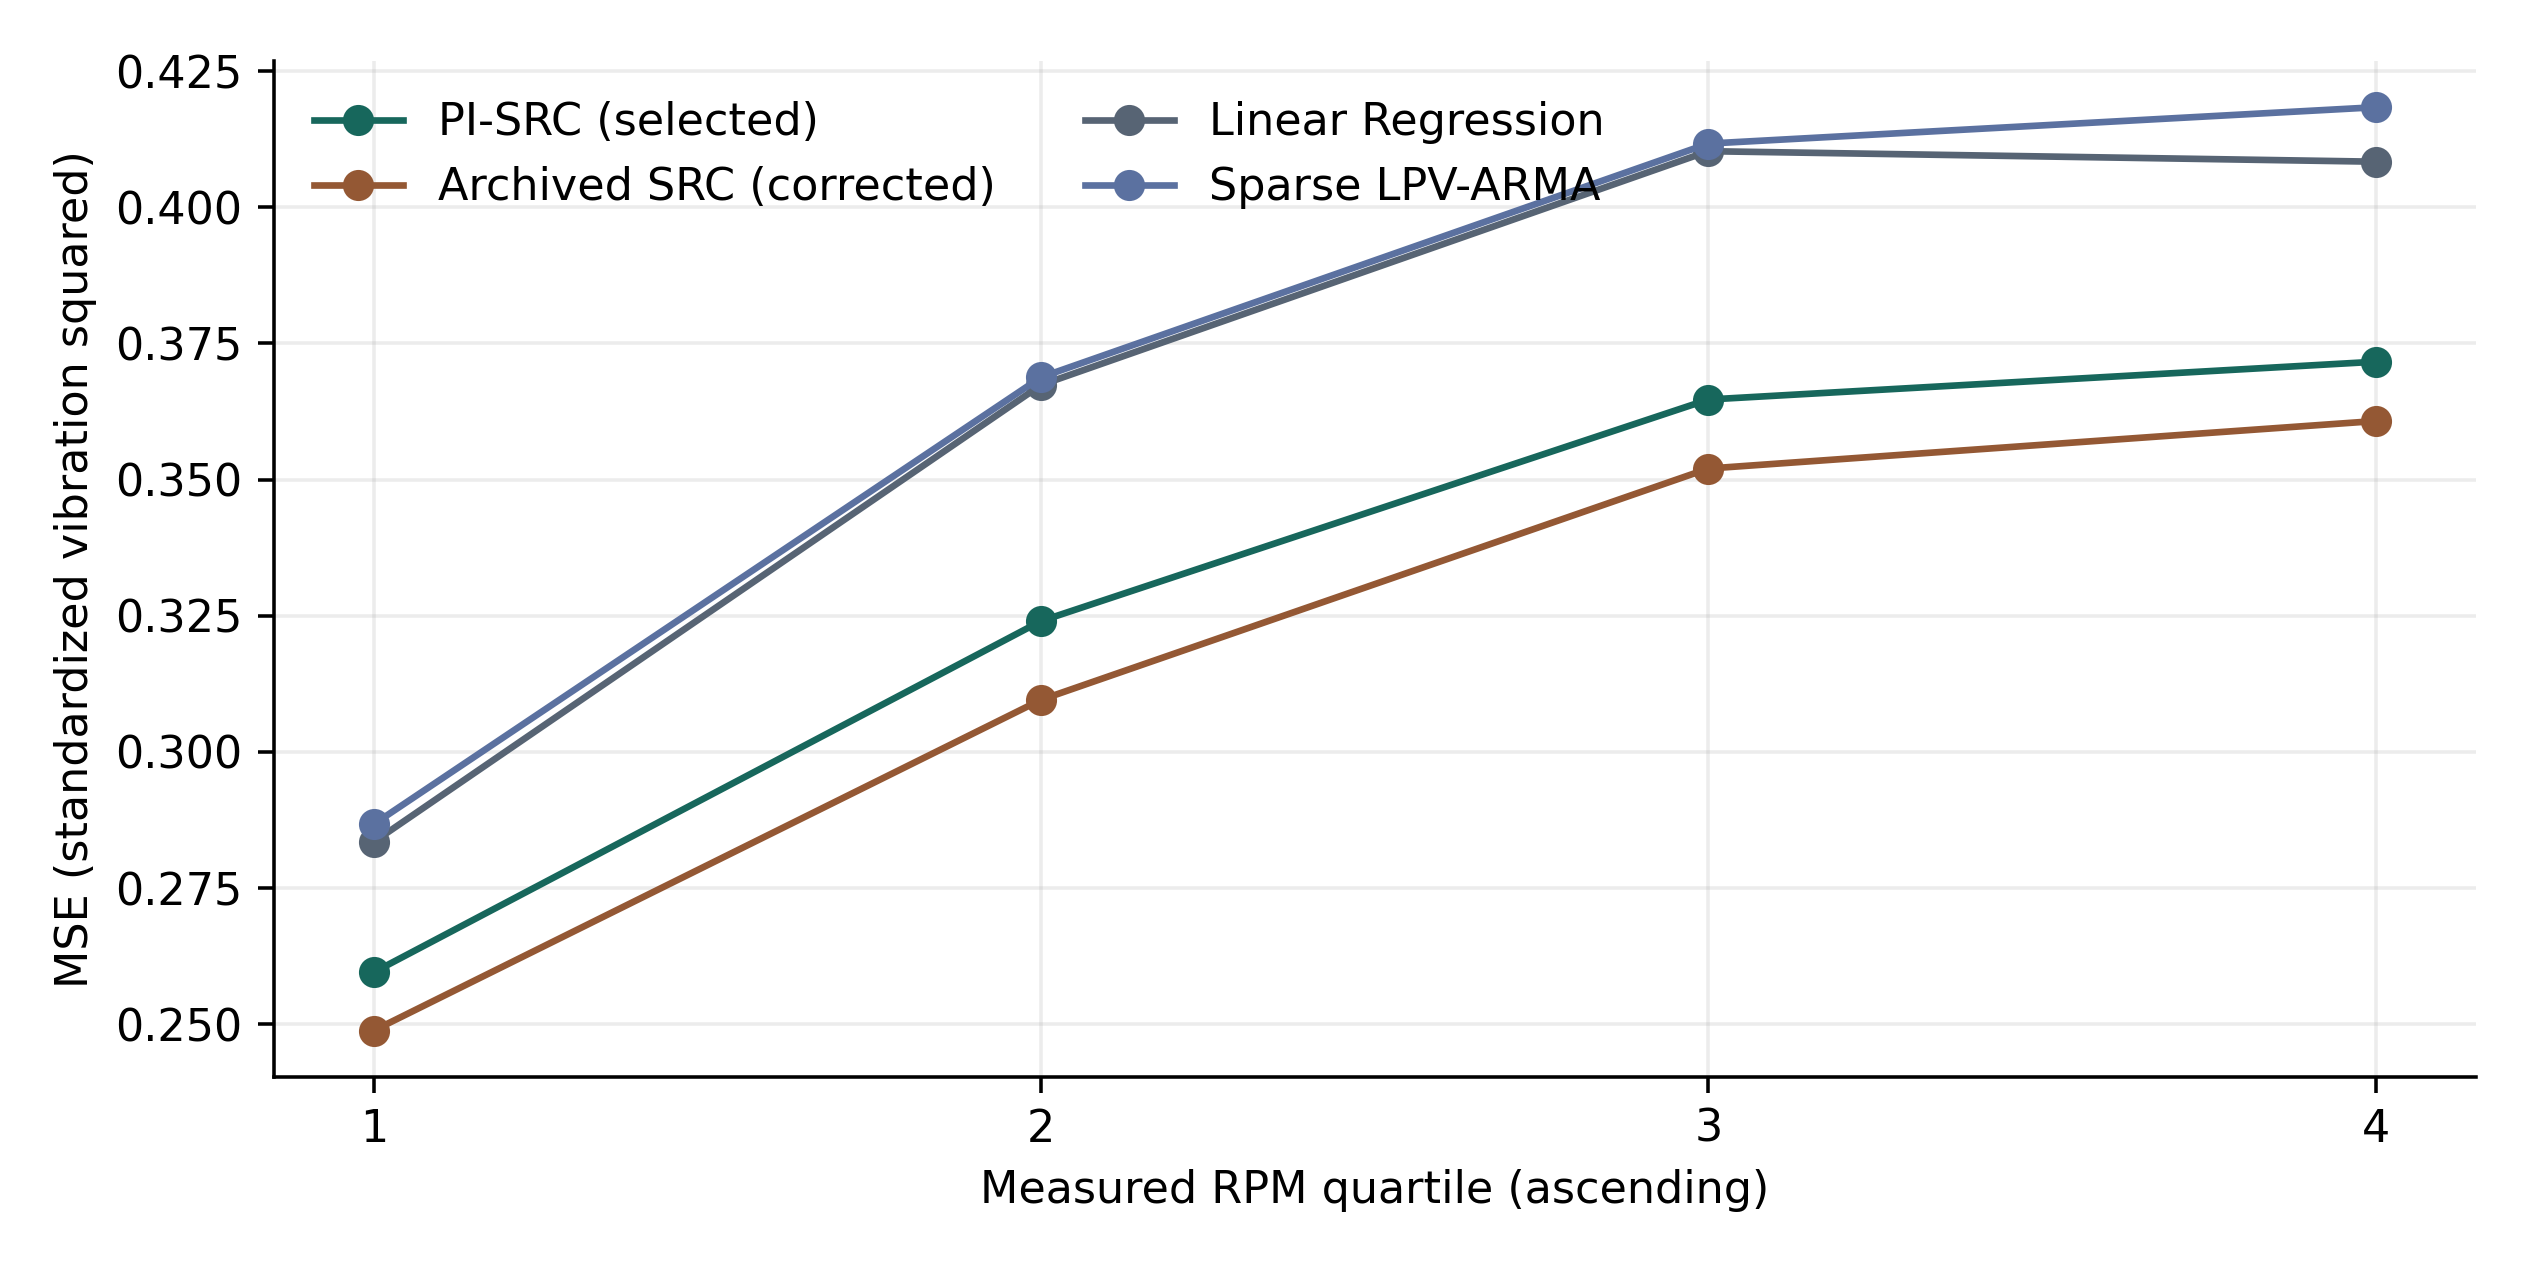

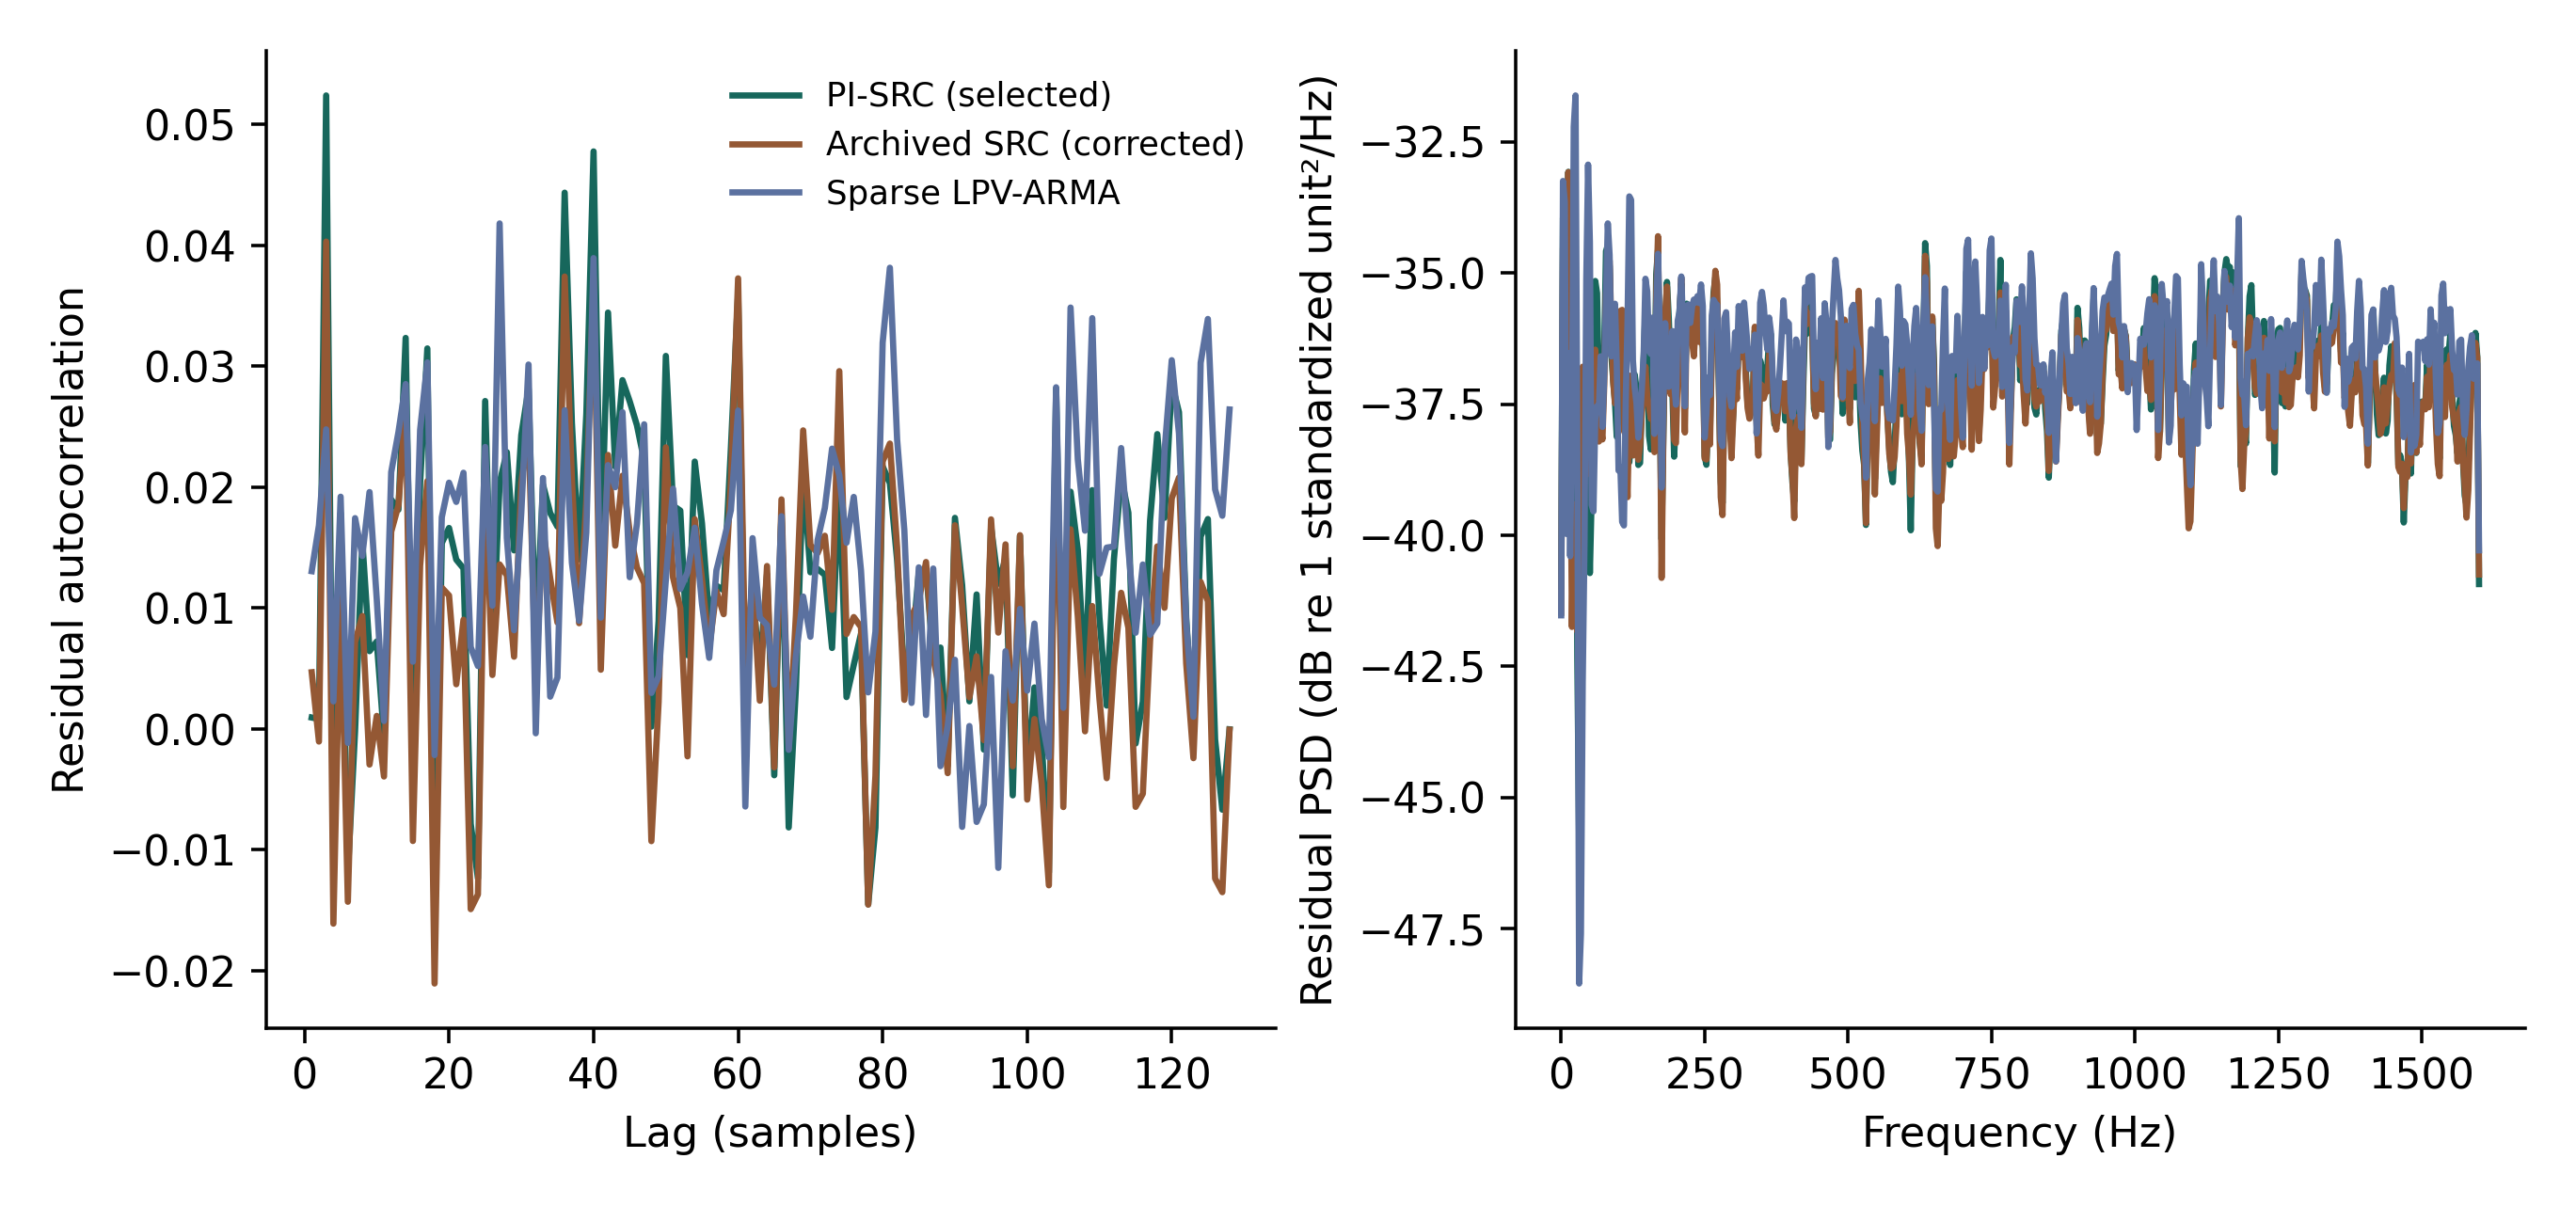

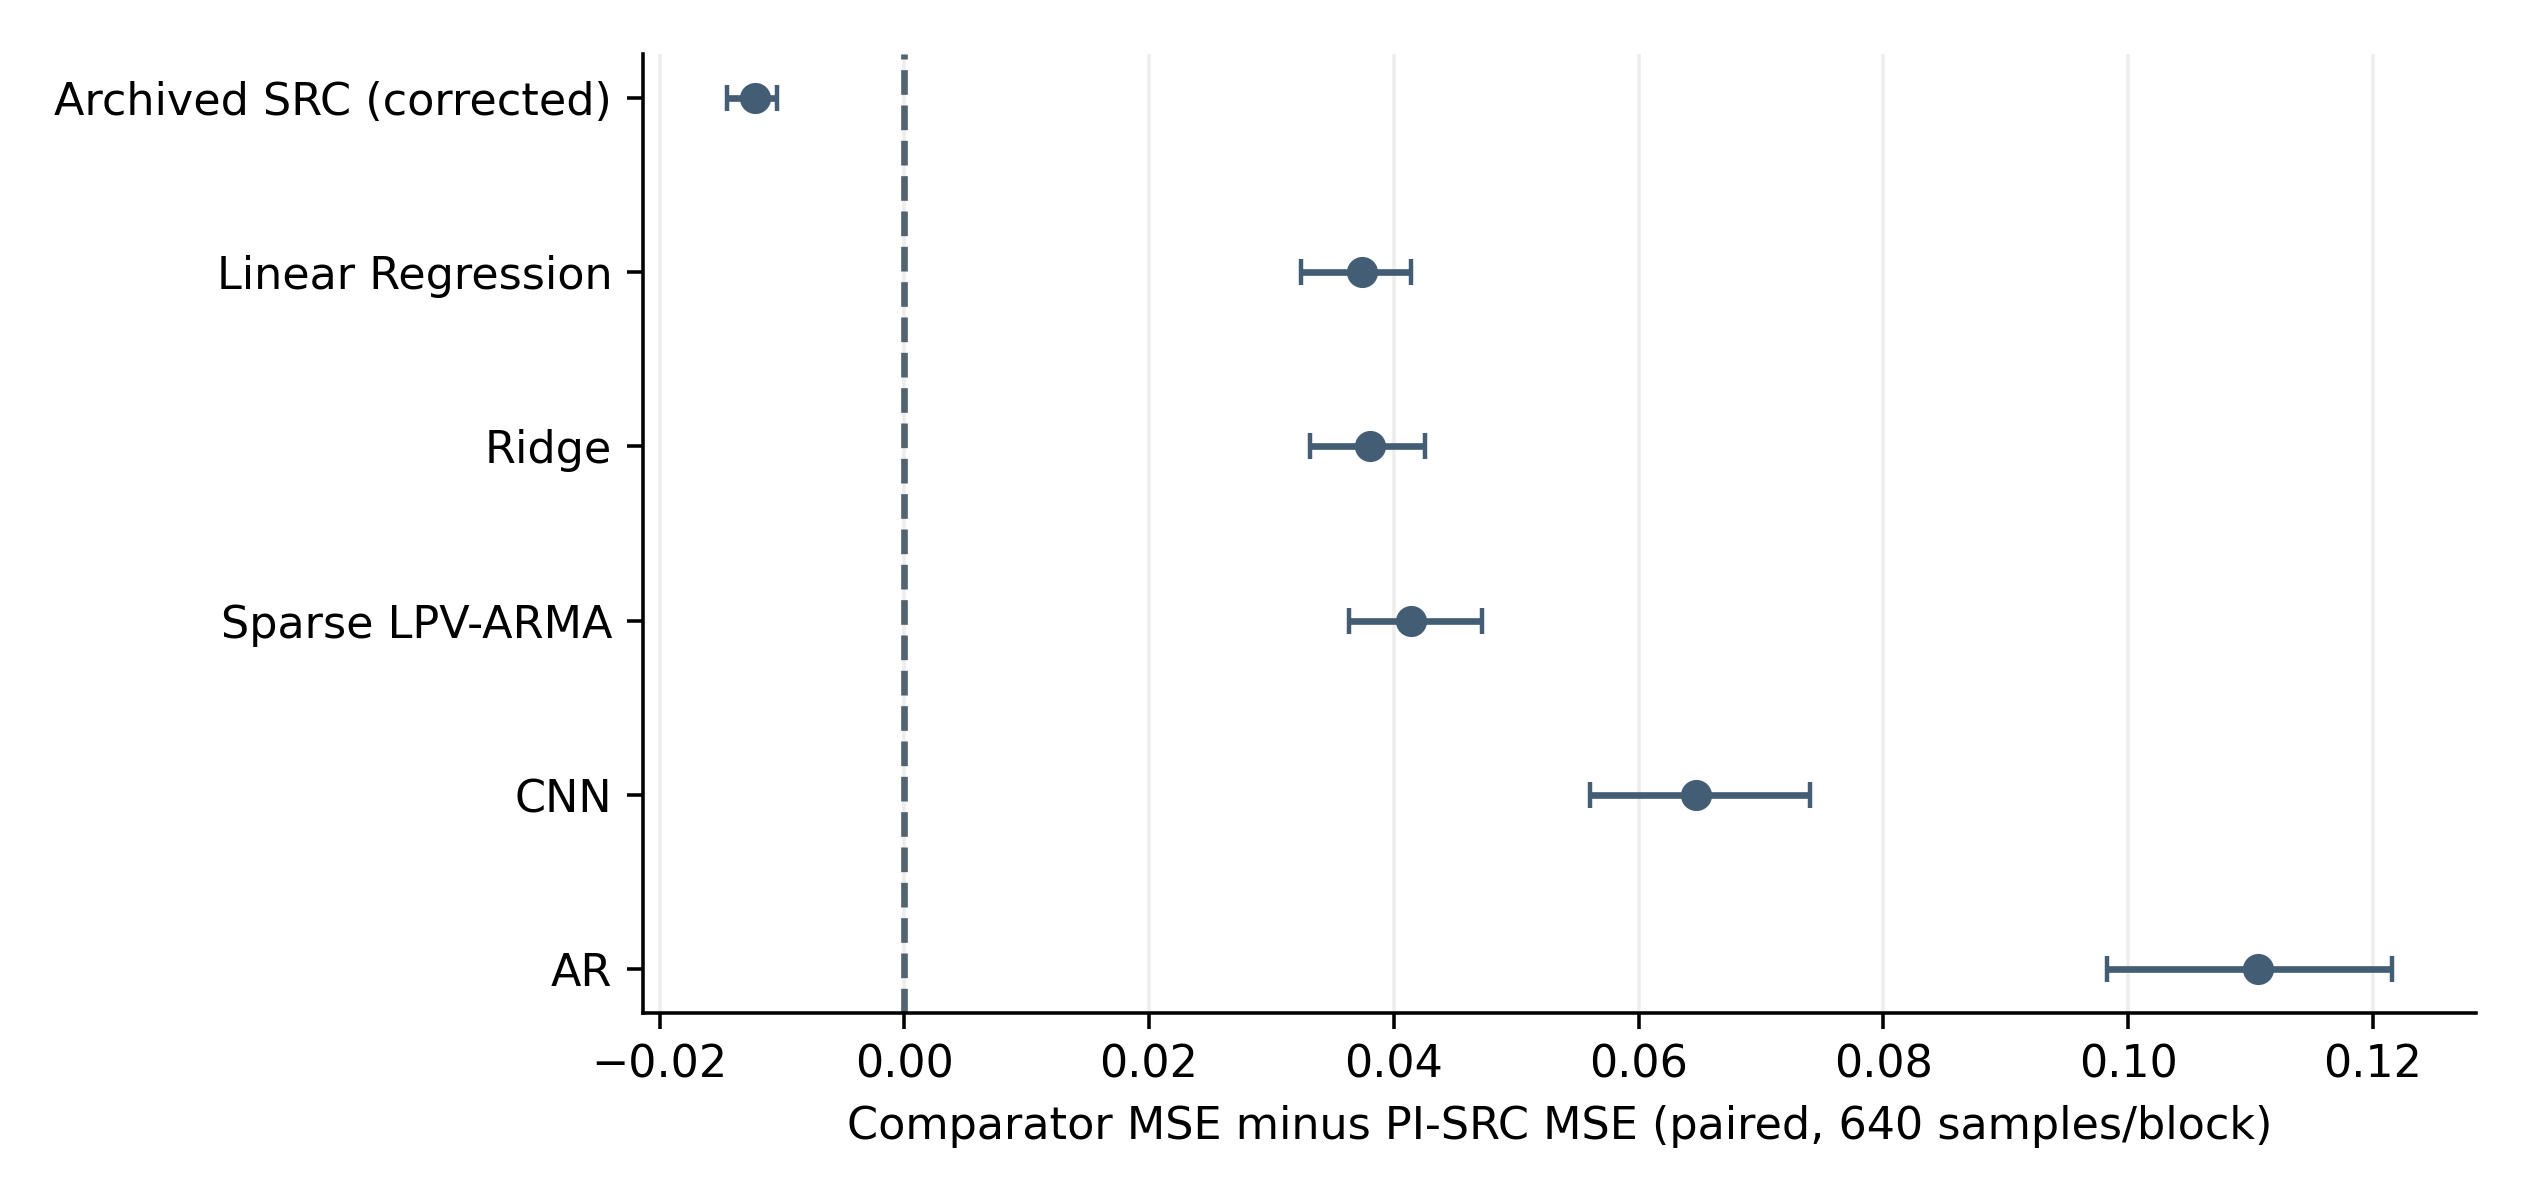

In [5]:
summary = evidence("results/metrics/comparison_summary.json")
if summary:
    print(f"Checked required families: {summary['required_baselines_checked']}/21")
    print(f"Selected minus archive MSE: {summary['primary_minus_anchor']:+.6f}")
    print(f"Selected improvement over leading required baseline: {summary['relative_improvement_over_required_baseline_pct']:.2f}%")
paired = table("results/statistical_tests/paired_moving_block.csv")
if paired is not None:
    display(paired.loc[paired.block_samples.eq(640) & paired.model.isin(
        ["archived_src_corrected","linear","sparse_lpv_arma","cnn","ar"])])
show_fig("figures/comparison/rpm_quartiles.png")
show_fig("figures/comparison/residual_structure.png")
show_fig("figures/comparison/paired_intervals.png")

### Interpretation and limits

Report the rank of the primary prespecified model even if a correction,
alternate search outcome, or historical forecast scores lower. Inputs
and device costs differ across model families. A common target mask is
necessary for fair evaluation but does not give every model the same
parameter count or effective number of training examples.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).